# Build a regression model

The real estate agency from D01's lab wants a first price model. One row is one house sale in Ames, Iowa, 2006 to 2010. You fit a linear regression on one column, then on all of them, and report the errors in dollars.

## Step 1 · Run the starter

The cell applies D01 6.4's decisions: it reads the file with `keep_default_na=False, na_values=[""]` (so the word `None` stays a category), removes the 4 houses over 4,000 sq ft, takes `y = np.log(SalePrice)`, drops `Id`, `SaleType` and `SaleCondition`, and splits 75 / 25 with `random_state=42`. It also builds D01's three-block `ColumnTransformer` as `pre`, with `make_pre(X)` to build the same blocks for another set of columns (the bonus uses it). Check the number of training and test houses.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("data/ames.csv", keep_default_na=False, na_values=[""])
df = df[df["GrLivArea"] <= 4000]
y = np.log(df["SalePrice"])
X = df.drop(columns=["Id", "SalePrice", "SaleType", "SaleCondition"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# D01 6.4: "no garage" and the like are categories; other gaps are imputed inside the pipeline
STRUCTURAL = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
              "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond", "PoolQC",
              "Fence", "MiscFeature"]


def make_pre(X):
    """D01 6.4's three-block ColumnTransformer for the columns X has."""
    num_cols = list(X.select_dtypes(include="number").columns)
    cat_cols = list(X.select_dtypes(include=["str", "object"]).columns)
    structural = [c for c in STRUCTURAL if c in cat_cols]
    other_cat = [c for c in cat_cols if c not in STRUCTURAL]
    blocks = [
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("none", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"),
                               OneHotEncoder(handle_unknown="ignore", sparse_output=False)), structural),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), other_cat),
    ]
    return ColumnTransformer([b for b in blocks if b[2]])


pre = make_pre(X)
print(len(X_train), "training houses,", len(X_test), "test houses,", X.shape[1], "feature columns")

1092 training houses, 364 test houses, 77 feature columns


## Step 2 · "Roughly, what is a square foot worth here?"

Translate: fit `LinearRegression()` on `X_train[["GrLivArea"]]` against the price in dollars, `np.exp(y_train)`. Print `coef_` and `intercept_`, and predict the price of a 1,500 sq ft house.

In [2]:
from sklearn.linear_model import LinearRegression

price_train, price_test = np.exp(y_train), np.exp(y_test)
one = LinearRegression().fit(X_train[["GrLivArea"]], price_train)
print("slope", one.coef_, "| intercept", one.intercept_)
pred_1500 = one.predict(pd.DataFrame({"GrLivArea": [1500]}))[0]
print("1,500 sq ft:", round(pred_1500))

slope [116.81356051] | intercept 5646.694104663649
1,500 sq ft: 180867


## Step 3 · Score the one-column model in dollars

MAE, RMSE and R² on the test houses (`mean_absolute_error`, `root_mean_squared_error`, `r2_score`). Then score a `DummyRegressor()` (it always predicts the mean training price) the same way.

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

p1 = one.predict(X_test[["GrLivArea"]])
print(f"one column: MAE {mean_absolute_error(price_test, p1):,.0f}, "
      f"RMSE {root_mean_squared_error(price_test, p1):,.0f}, R² {r2_score(price_test, p1):.3f}")
mean_model = DummyRegressor().fit(X_train[["GrLivArea"]], price_train)
pm = mean_model.predict(X_test[["GrLivArea"]])
print(f"the mean:   MAE {mean_absolute_error(price_test, pm):,.0f}, "
      f"RMSE {root_mean_squared_error(price_test, pm):,.0f}, R² {r2_score(price_test, pm):.3f}")

one column: MAE 37,880, RMSE 52,336, R² 0.453
the mean:   MAE 57,043, RMSE 71,312, R² -0.015


## Step 4 · Every column

`make_pipeline(pre, LinearRegression())`, fitted on `X_train, y_train` (the log price). Predict the test houses, turn the predictions back into dollars with `np.exp`, and print MAE, RMSE and R² in dollars. Print R² on the training houses too.

In [4]:
model = make_pipeline(pre, LinearRegression()).fit(X_train, y_train)
pred = np.exp(model.predict(X_test))                 # log prices back to dollars
mae, rmse, r2 = mean_absolute_error(price_test, pred), root_mean_squared_error(price_test, pred), r2_score(price_test, pred)
r2_train = r2_score(price_train, np.exp(model.predict(X_train)))
print(f"test: MAE {mae:,.0f}, RMSE {rmse:,.0f}, R² {r2:.3f} | training R² {r2_train:.3f}")

test: MAE 15,354, RMSE 22,091, R² 0.903 | training R² 0.956


## Step 5 · The residuals

Plot predicted price on the x-axis and actual minus predicted on the y-axis. Find the house with the largest miss and print its living area, neighborhood, actual and predicted price.

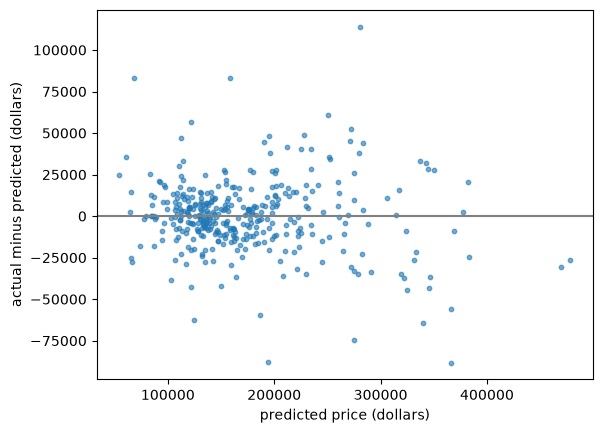

1973 sq ft, NridgHt, actual 395000, predicted 280974


In [5]:
resid = price_test - pred
plt.scatter(pred, resid, s=10, alpha=0.6)
plt.axhline(0, color="gray")
plt.xlabel("predicted price (dollars)")
plt.ylabel("actual minus predicted (dollars)")
plt.show()
worst = resid.abs().idxmax()
worst_house = (f"{X_test.loc[worst, 'GrLivArea']} sq ft, {X_test.loc[worst, 'Neighborhood']}, "
               f"actual {round(price_test[worst])}, predicted {round(pred[X_test.index.get_loc(worst)])}")
print(worst_house)

## Step 6 · "How far off is a typical estimate?"

Answer in one sentence with the MAE from step 4, and add the median of `abs(predicted / actual - 1)` as a percentage.

In [6]:
median_pct = np.median(np.abs(pred / price_test - 1))
print(f"A typical estimate is off by about {mae:,.0f} dollars; half the estimates are within "
      f"{median_pct:.1%} of the sale price.")

A typical estimate is off by about 15,354 dollars; half the estimates are within 6.5% of the sale price.


## Bonus · `TotalSF`, then five columns

In [7]:
def add_total_sf(d):
    d = d.copy()
    d["TotalSF"] = d["TotalBsmtSF"].fillna(0) + d["1stFlrSF"] + d["2ndFlrSF"]
    return d


Xs_train, Xs_test = add_total_sf(X_train), add_total_sf(X_test)
m_sf = make_pipeline(make_pre(Xs_train), LinearRegression()).fit(Xs_train, y_train)
rmse_sf = root_mean_squared_error(price_test, np.exp(m_sf.predict(Xs_test)))
print(f"with TotalSF: RMSE {rmse_sf:,.0f}")

five = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt"]
m5 = make_pipeline(make_pre(X_train[five]), LinearRegression()).fit(X_train[five], y_train)
p5 = np.exp(m5.predict(X_test[five]))
print(f"five columns: RMSE {root_mean_squared_error(price_test, p5):,.0f}, R² {r2_score(price_test, p5):.3f}")

with TotalSF: RMSE 22,091
five columns: RMSE 27,035, R² 0.854


## Check yourself

In [8]:
check = {
    "Step 1 · training houses": len(X_train),
    "Step 1 · test houses": len(X_test),
    "Step 1 · feature columns": X.shape[1],
    "Step 2 · slope": round(one.coef_[0], 1),
    "Step 2 · slope, two decimals": f"{one.coef_[0]:.2f}",
    "Step 2 · intercept": round(one.intercept_),
    "Step 2 · 1,500 sq ft predicts": round(pred_1500),
    "Step 3 · one column MAE": round(mean_absolute_error(price_test, p1)),
    "Step 3 · one column RMSE": round(root_mean_squared_error(price_test, p1)),
    "Step 3 · one column R²": round(r2_score(price_test, p1), 3),
    "Step 3 · the mean RMSE": round(root_mean_squared_error(price_test, pm)),
    "Step 3 · the mean R²": round(r2_score(price_test, pm), 3),
    "Step 4 · test MAE": round(mae),
    "Step 4 · test RMSE": round(rmse),
    "Step 4 · test R²": round(r2, 3),
    "Step 4 · training R²": round(r2_train, 3),
    "Step 5 · largest miss": worst_house,
    "Step 6 · median error": round(median_pct, 3),
    "Bonus · TotalSF RMSE": round(rmse_sf),
    "Bonus · five columns RMSE": round(root_mean_squared_error(price_test, p5)),
    "Bonus · five columns R²": round(r2_score(price_test, p5), 3),
}
for label, value in check.items():
    print(f"{label:<32} {value}")

Step 1 · training houses         1092
Step 1 · test houses             364
Step 1 · feature columns         77
Step 2 · slope                   116.8
Step 2 · slope, two decimals     116.81
Step 2 · intercept               5647
Step 2 · 1,500 sq ft predicts    180867
Step 3 · one column MAE          37880
Step 3 · one column RMSE         52336
Step 3 · one column R²           0.453
Step 3 · the mean RMSE           71312
Step 3 · the mean R²             -0.015
Step 4 · test MAE                15354
Step 4 · test RMSE               22091
Step 4 · test R²                 0.903
Step 4 · training R²             0.956
Step 5 · largest miss            1973 sq ft, NridgHt, actual 395000, predicted 280974
Step 6 · median error            0.065
Bonus · TotalSF RMSE             22091
Bonus · five columns RMSE        27035
Bonus · five columns R²          0.854
